# Airline Spark demo

## 1. Connect


In [1]:
from pathlib import Path
from time import perf_counter
import json
import sys
from IPython.display import HTML, display

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "conf/project.yaml").is_file())
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))
from pyspark.sql import functions as F
from airline.common.config import load_config
from airline.common.paths import get_project_paths
from airline.common.spark_session import create_spark_session

paths = get_project_paths(load_config())
artifacts = paths.resolve(paths.artifact_root)
spark = create_spark_session("airline-runnable-demo")
spark.sparkContext.setLogLevel("ERROR")
print(f"Spark {spark.version} | {spark.sparkContext.master}")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
26/10/28 06:35:36 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Spark 3.5.9 | spark://spark-master:7077


## 2. Validate inputs


In [2]:
import csv
import re

csv_files = sorted(paths.resolve(paths.raw_csv).glob("*.csv"))
pattern = re.compile(r"_(2023|2024)_(\d{1,2})\.csv$")
observed = {(int(m[1]), int(m[2])) for p in csv_files if (m := pattern.search(p.name))}
assert len(csv_files) == 24
assert observed == {(year, month) for year in (2023, 2024) for month in range(1, 13)}
headers = []
for path in csv_files:
    with path.open(encoding="utf-8-sig", newline="") as handle:
        headers.append(tuple(next(csv.reader(handle))))
assert all(header == headers[0] for header in headers)
assert {"FlightDate", "Reporting_Airline", "Cancelled", "Diverted", "ArrDelayMinutes"} <= set(headers[0])
print(f"PASS: {len(csv_files)} monthly files, complete coverage, {len(headers[0])} consistent columns")

PASS: 24 monthly files, complete coverage, 110 consistent columns


## 3. Explore delays


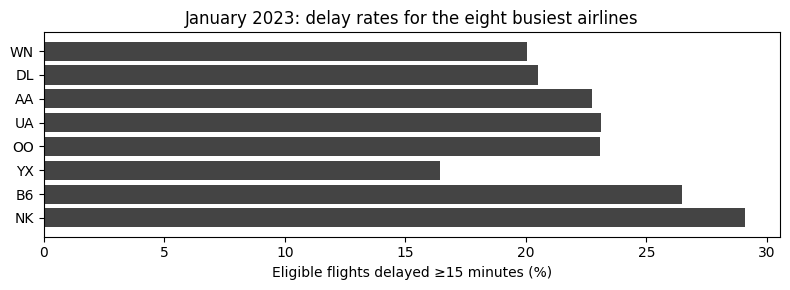

+-----------+-----------------+-----------------+----------------------+--------------+
|flight_date|reporting_airline|scheduled_flights|eligible_delay_flights|delay_rate_pct|
+-----------+-----------------+-----------------+----------------------+--------------+
|2023-01-01 |9E               |350              |348                   |12.64         |
|2023-01-01 |AA               |2234             |2229                  |19.02         |
|2023-01-01 |AS               |612              |588                   |26.7          |
|2023-01-01 |B6               |722              |698                   |47.99         |
+-----------+-----------------+-----------------+----------------------+--------------+
only showing top 4 rows



In [3]:
import matplotlib.pyplot as plt
from airline.dws.daily_metrics import validate_daily_source
from airline.dws.build_carrier_daily import GRAIN_COLUMNS, transform_carrier_daily

flights = spark.read.parquet(str(paths.resolve(paths.dwd_flights))).filter(
    (F.col("year") == 2023) & (F.col("month") == 1))
validate_daily_source(flights, GRAIN_COLUMNS)
completed = flights.filter((F.col("is_cancelled") == 0) & (F.col("is_diverted") == 0)
                           & F.col("is_arrival_delayed_15m").isNotNull())
airlines = completed.groupBy("reporting_airline").agg(
    F.count("*").alias("flights"),
    (100 * F.avg("is_arrival_delayed_15m")).alias("delay_rate_pct"))
rows = airlines.orderBy(F.desc("flights"), "reporting_airline").limit(8).collect()
fig, ax = plt.subplots(figsize=(8, 3))
ax.barh([r.reporting_airline for r in rows], [r.delay_rate_pct for r in rows], color="#444")
ax.invert_yaxis()
ax.set(title="January 2023: delay rates for the eight busiest airlines", xlabel="Eligible flights delayed ≥15 minutes (%)")
plt.tight_layout()
plt.show()
plt.close(fig)

daily = transform_carrier_daily(flights)
daily.orderBy("flight_date", "reporting_airline").select(
    "flight_date", "reporting_airline", "scheduled_flights", "eligible_delay_flights",
    F.round(100 * F.col("delay_rate"), 2).alias("delay_rate_pct")).show(4, truncate=False)

## 4. Eligibility and chronology


In [4]:
from datetime import date
from airline.dws.ml_feature_contract import FEATURE_COLUMNS, LEAKAGE_BLACKLIST, SPLIT_BOUNDARIES
from airline.dws.build_ml_flight_features import assign_chronological_split

eligible = completed.filter(F.col("flight_date").isNotNull())
eligible.agg(F.count("*").alias("eligible_rows"),
             F.sum("is_arrival_delayed_15m").alias("delayed_rows")).show()
assert not set(FEATURE_COLUMNS) & LEAKAGE_BLACKLIST
boundary_dates = spark.createDataFrame([(date.fromisoformat(d),) for d in
    ["2024-04-30", "2024-05-01", "2024-08-31", "2024-09-01"]], "flight_date date")
assigned = assign_chronological_split(boundary_dates).orderBy("flight_date").collect()
assert [r.split for r in assigned] == ["train", "validation", "validation", "test"]
for row in assigned:
    print(row.flight_date, "→", row.split)
print("PASS: target outcome fields excluded from the production feature vector")

+-------------+------------+
|eligible_rows|delayed_rows|
+-------------+------------+
|       527197|      116713|
+-------------+------------+



2024-04-30 → train
2024-05-01 → validation
2024-08-31 → validation
2024-09-01 → test
PASS: target outcome fields excluded from the production feature vector


## 5. Partitions and reuse


In [5]:
from contextlib import redirect_stdout
from io import StringIO

def show_plan(frame):
    output = StringIO()
    with redirect_stdout(output):
        frame.explain("formatted")
    print(output.getvalue().split("\n\n", 1)[0])

partition_base = spark.range(0, 1000, numPartitions=8)
for name, frame in [("repartition", partition_base.repartition(4)),
                    ("coalesce", partition_base.coalesce(4))]:
    print(f"{name}: 8 → {frame.rdd.getNumPartitions()} partitions")
    show_plan(frame)
    assert frame.count() == 1000
print("PASS: both retain 1,000 rows; repartition adds an exchange")

repartition: 8 → 4 partitions
== Physical Plan ==
AdaptiveSparkPlan (5)
+- == Final Plan ==
   ShuffleQueryStage (3), Statistics(sizeInBytes=15.6 KiB, rowCount=1.00E+3)
   +- Exchange (2)
      +- * Range (1)
+- == Initial Plan ==
   Exchange (4)
   +- Range (1)
coalesce: 8 → 4 partitions
== Physical Plan ==
Coalesce (2)
+- * Range (1)
PASS: both retain 1,000 rows; repartition adds an exchange


In [6]:
measurements = []
for cached in (False, True):
    frame = transform_carrier_daily(flights)
    if cached:
        frame = frame.cache()
    try:
        start = perf_counter()
        first = frame.agg(F.sum("scheduled_flights")).first()[0]
        first_seconds = perf_counter() - start
        start = perf_counter()
        second = frame.agg(F.sum("scheduled_flights")).first()[0]
        second_seconds = perf_counter() - start
        assert first == second
        measurements.append((first, first_seconds, second_seconds))
        print(f"cache={cached}: first={first_seconds:.2f}s, second={second_seconds:.2f}s; flights={first:,}")
    finally:
        if cached:
            frame.unpersist(blocking=True)
assert measurements[0][0] == measurements[1][0]
print("PASS: results identical across both variants")

cache=False: first=1.10s, second=0.90s; flights=538,837


cache=True: first=2.42s, second=0.28s; flights=538,837
PASS: results identical across both variants


## 6. Build causal history


In [7]:
from airline.dws.build_ml_flight_features import entity_history

minute_us = 60 * 1_000_000
fixture = spark.createDataFrame([
    ("AA", 540 * minute_us, 725 * minute_us, 1),  # source: 09:00 → 12:05
    ("AA", 720 * minute_us, None, 0),            # target: 12:00
    ("AA", 725 * minute_us, None, 0),            # target: 12:05
    ("AA", 726 * minute_us, None, 0),            # target: 12:06
], "reporting_airline string, _prediction_us long, _available_us long, is_arrival_delayed_15m int")
history = entity_history(fixture, "carrier", ("reporting_airline",))
checks = history.filter(F.col("_prediction_us") >= 720 * minute_us).orderBy("_prediction_us")
rows = checks.select("_prediction_us", "carrier_flight_count_7d", "carrier_delay_rate_7d").collect()
assert [r.carrier_flight_count_7d for r in rows] == [0, 0, 1]
for row in rows:
    minutes = row._prediction_us // minute_us
    print(f"{minutes // 60:02d}:{minutes % 60:02d} | history count: {row.carrier_flight_count_7d}"
          f" | delay rate: {row.carrier_delay_rate_7d}")

12:00 | history count: 0 | delay rate: None
12:05 | history count: 0 | delay rate: None
12:06 | history count: 1 | delay rate: 1.0


## 7. Fit a small model


In [8]:
from pyspark import StorageLevel
from airline.ml.preprocessing import build_preprocessing_pipeline
from airline.ml.model_contract import build_logistic_regression, POSITIVE_CLASS_WEIGHT
from airline.dws.ml_feature_contract import TARGET_COLUMN

training_demo = spark.read.parquet(str(paths.resolve(paths.dws_ml_flight_features))).filter(
    (F.col("split") == "train") & F.col("flight_date").between("2023-02-01", "2023-02-07")
).limit(1000).persist(StorageLevel.DISK_ONLY)
prepared_demo = None
try:
    training_rows = training_demo.count()
    assert training_rows > 0
    demo_preprocessing = build_preprocessing_pipeline().fit(training_demo)
    prepared_demo = demo_preprocessing.transform(training_demo).withColumn(
        "class_weight", F.when(F.col(TARGET_COLUMN) == 1, POSITIVE_CLASS_WEIGHT).otherwise(1.0)
    ).select("features", TARGET_COLUMN, "class_weight").persist(StorageLevel.DISK_ONLY)
    demo_model = build_logistic_regression().setMaxIter(5).fit(prepared_demo)
    print(f"LIVE FIT: {training_rows} training rows, {demo_model.numFeatures} vector dimensions, "
          f"{demo_model.summary.totalIterations} iterations")
    demo_model.transform(prepared_demo).select(TARGET_COLUMN, "probability", "prediction").show(4, truncate=False)
finally:
    if prepared_demo is not None:
        prepared_demo.unpersist()
    training_demo.unpersist()

LIVE FIT: 1000 training rows, 342 vector dimensions, 5 iterations
+----------------------+----------------------------------------+----------+
|is_arrival_delayed_15m|probability                             |prediction|
+----------------------+----------------------------------------+----------+
|1                     |[0.7958281840369557,0.20417181596304435]|0.0       |
|0                     |[0.848878164327058,0.15112183567294202] |0.0       |
|0                     |[0.8233270399439592,0.17667296005604083]|0.0       |
|0                     |[0.8380861852371165,0.16191381476288347]|0.0       |
+----------------------+----------------------------------------+----------+
only showing top 4 rows



## 8. Select and score


In [9]:
from airline.ml.experiments import best_threshold, select_classifier
from airline.ml.model_contract import load_bundle

preprocessing, classifier, manifest = load_bundle(artifacts / "models")
candidates = {name: best_threshold(result["thresholds"])
              for name, result in manifest["selection"]["validation_results"].items()}
winner = select_classifier(candidates)
threshold = candidates[winner]["step"] / 100
assert (winner, threshold) == (manifest["selected_classifier"], manifest["threshold"])
print(f"Verified winner: {winner.upper()} | threshold: {threshold}")

Verified winner: LR | threshold: 0.39


In [10]:
from airline.ml.evaluate import score
from airline.ml.metrics import calculate_metrics

sample = spark.read.parquet(str(paths.resolve(paths.dws_ml_test_features))).filter(
    F.col("split") == "test").limit(1000)
scored = score(preprocessing, classifier, sample, threshold).cache()
try:
    scored.select("flight_date", "reporting_airline", "is_arrival_delayed_15m",
                  F.round("probability", 4).alias("probability"), "prediction").show(8)
    demo_metrics = calculate_metrics(scored, threshold)
    assert demo_metrics["rows"] == 1000
    print("Live sample:", {k: round(demo_metrics[k], 4) for k in ["rows", "precision", "recall", "f1"]})
finally:
    scored.unpersist()

+-----------+-----------------+----------------------+-----------+----------+
|flight_date|reporting_airline|is_arrival_delayed_15m|probability|prediction|
+-----------+-----------------+----------------------+-----------+----------+
| 2024-09-01|               F9|                     0|     0.3496|         0|
| 2024-09-01|               AA|                     0|     0.3719|         0|
| 2024-09-01|               DL|                     0|     0.2667|         0|
| 2024-09-01|               HA|                     0|     0.3249|         0|
| 2024-09-01|               B6|                     0|     0.3156|         0|
| 2024-09-01|               YX|                     0|     0.2623|         0|
| 2024-09-01|               F9|                     0|     0.2963|         0|
| 2024-09-01|               F9|                     0|     0.3182|         0|
+-----------+-----------------+----------------------+-----------+----------+
only showing top 8 rows

Live sample: {'rows': 1000, 'precision'

## 9. Evaluate


In [11]:
reports = {split: json.loads((artifacts / "metrics" / f"{split}.json").read_text())
           for split in ("validation", "test")}
assert all(r["bundle_id"] == manifest["bundle_id"] for r in reports.values())
chart = ['<div style="max-width:800px;background:white;color:#111;padding:16px;font:18px sans-serif">',
         '<b>Saved full-data performance · higher is better · scale 0–1</b>']
for metric in ("pr_auc", "roc_auc", "f1"):
    chart.append(f'<p><b>{metric.upper()}</b></p>')
    for split, color in [("validation", "#111"), ("test", "#888")]:
        value = reports[split][metric]
        chart.append(f'<div style="display:flex;gap:12px;align-items:center;margin:8px 0">'
                     f'<span style="width:130px">{split}</span>'
                     f'<div style="flex:1;background:#eee;height:22px">'
                     f'<div style="width:{value * 100}%;height:22px;background:{color}"></div></div>'
                     f'<span>{value:.4f}</span></div>')
display(HTML(''.join(chart) + '</div>'))

## 10. Verify recovery


In [12]:
evidence_path = ROOT / "artifacts/fault_tolerance/final-location/verification.json"
evidence = json.loads(evidence_path.read_text())
failed, retried = evidence["failed_task"], evidence["successful_retry"]
a, b = failed["Task Info"], retried["Task Info"]
assert failed["Task End Reason"]["Reason"] == "ExecutorLostFailure"
assert retried["Task End Reason"]["Reason"] == "Success"
assert failed["Stage ID"] == retried["Stage ID"] and a["Index"] == b["Index"]
assert b["Attempt"] > a["Attempt"] and a["Executor ID"] != b["Executor ID"]
assert evidence["status"] == "passed" and evidence["sum"] == 499500
print(f"PASS: stage {failed['Stage ID']}, partition {a['Index']}: "
      f"{a['Host']} attempt {a['Attempt']} → {b['Host']} attempt {b['Attempt']}")
print(f"Saved recovered output: {evidence['rows']} records, {evidence['groups']} groups, sum {evidence['sum']}")

PASS: stage 2, partition 1: worker1 attempt 0 → worker2 attempt 1
Saved recovered output: 1000 records, 10 groups, sum 499500


## 11. Finish


In [13]:
spark.stop()